## Baixando os dados

In [ ]:
from google.colab import files
files.upload()

In [ ]:
!ls -lh

total 59M
-rw-r--r-- 1 root root  25M Oct  7 14:58 156_2023.csv
-rw-r--r-- 1 root root  18M Oct  7 14:58 156_2024.csv
-rw-r--r-- 1 root root  15M Oct  7 14:58 156_2025.csv
-rw-r--r-- 1 root root 2.1M Oct  7 15:29 bairros.geojson
drwxr-xr-x 1 root root 4.0K Oct  2 13:50 sample_data


## limpando base de dados

In [ ]:
!pip install pyarrow -q
import pandas as pd, numpy as np, re, unicodedata
import matplotlib.pyplot as plt

def sem_acento(s):
    s = unicodedata.normalize("NFKD", str(s))
    return "".join(c for c in s if not unicodedata.combining(c))

def norm_texto(s):
    """MAIÚSCULO, sem acento, sem espaços repetidos"""
    if pd.isna(s): return s
    return re.sub(r"\s+", " ", sem_acento(s).upper().strip())

# tabela de perdas: registra quantas linhas entram e saem em cada etapa
perdas = []
def log(etapa, antes, depois, obs=""):
    perdas.append({"etapa": etapa, "entrou": antes, "saiu": depois,
                   "perdeu": antes - depois, "obs": obs})
    print(f"{etapa}: {antes:,} -> {depois:,} (perdeu {antes-depois:,}) {obs}")

## juntando 3 anos

In [ ]:
def ler_csv(caminho):
    for enc in ("utf-8", "latin-1"):
        for sep in (";", ","):
            try:
                d = pd.read_csv(caminho, sep=sep, encoding=enc, dtype=str, low_memory=False)
                if d.shape[1] > 3:
                    return d
            except Exception:
                pass
    raise ValueError(f"Não consegui ler {caminho}")

partes = []
for ano in [2023, 2024, 2025]:
    d = ler_csv(f"156_{ano}.csv")
    d.columns = [re.sub(r"\W+", "_", norm_texto(c)).strip("_") for c in d.columns]
    d["ANO_ARQUIVO"] = ano
    print(ano, d.shape)
    partes.append(d)

df = pd.concat(partes, ignore_index=True)
log("0 juntar 2023-2025", len(df), len(df))
print(list(df.columns))
df.head()

2023 (93555, 14)
2024 (108082, 14)
2025 (86966, 14)
0 juntar 2023-2025: 288,603 -> 288,603 (perdeu 0) 
['GRUPOSERVICO_CODIGO', 'GRUPOSERVICO_DESCRICAO', 'SERVICO_CODIGO', 'SERVICO_DESCRICAO', 'LOGRADOURO', 'NUMERO', 'BAIRRO', 'RPA', 'DATA_DEMANDA', 'SITUACAO', 'DATA_ULT_SITUACAO', 'LATITUDE', 'LONGITUDE', 'ANO_ARQUIVO']


,GRUPOSERVICO_CODIGO,GRUPOSERVICO_DESCRICAO,SERVICO_CODIGO,SERVICO_DESCRICAO,LOGRADOURO,NUMERO,BAIRRO,RPA,DATA_DEMANDA,SITUACAO,DATA_ULT_SITUACAO,LATITUDE,LONGITUDE,ANO_ARQUIVO
0,11,DRENAGEM,97,RECUP.DE CANALETAS DE DRENAGEM ...,1sb corrego da loura,,BREJO DA GUABIRABA,3,2023-05-16,CADASTRADA,2023-05-16,-7.9961436,-34.9362847,2023
1,20,LIMPEZA URBANA,41,CAPINAO EM VIA PAVIMENTADA ...,1sb corrego do leoncio,,NOVA DESCOBERTA,3,2023-06-01,ATENDIDA,2023-07-27,-8.0028869,-34.9274109,2023
2,20,LIMPEZA URBANA,41,CAPINAO EM VIA PAVIMENTADA ...,1sb barao camaqua,,NOVA DESCOBERTA,3,2023-03-09,ATENDIDA,2023-04-27,-8.0059289,-34.9229936,2023
3,20,LIMPEZA URBANA,41,CAPINAO EM VIA PAVIMENTADA ...,1sb barao camaqua,,NOVA DESCOBERTA,3,2023-09-13,ATENDIDA,2023-12-11,-8.0059289,-34.9229936,2023
4,17,ILUMINAO PBLICA,21,APAGAR LAMPADA ...,1tr aguia branca,,NOVA DESCOBERTA,3,2023-03-29,ATENDIDA,2023-09-04,-8.0032816,-34.9281972,2023


In [ ]:
df.columns

Index(['GRUPOSERVICO_CODIGO', 'GRUPOSERVICO_DESCRICAO', 'SERVICO_CODIGO',
       'SERVICO_DESCRICAO', 'LOGRADOURO', 'NUMERO', 'BAIRRO', 'RPA',
       'DATA_DEMANDA', 'SITUACAO', 'DATA_ULT_SITUACAO', 'LATITUDE',
       'LONGITUDE', 'ANO_ARQUIVO'],
      dtype='object')

## filtrar Limpeza Urbana e Drenagem

In [ ]:
df["GRUPO"] = df["GRUPOSERVICO_DESCRICAO"].map(norm_texto)
df["GRUPO"].value_counts().head(20)

,count
GRUPO,
ILUMINACAO PUBLICA,80778
LIMPEZA URBANA,51858
DRENAGEM,35979
ILUMINAO PBLICA,35178
ARBORIZACAO,20883
ARBORIZAO,12076
PAVIMENTACAO,8814
PAVIMENTAO,5666
ESCADARIA,5306


## Aplicação de filtro e remoção de duplicadas

In [ ]:
TERMOS = ["LIMPEZA URBANA", "DRENAGEM"]   # ajuste conforme os nomes que você viu

n = len(df)
df = df[df["GRUPO"].fillna("").apply(lambda g: any(t in g for t in TERMOS))].copy()
log("1 filtrar recorte", n, len(df))

n = len(df)
df = df.drop_duplicates()
log("2 duplicatas exatas", n, len(df))

1 filtrar recorte: 288,603 -> 91,140 (perdeu 197,463) 
2 duplicatas exatas: 91,140 -> 91,140 (perdeu 0) 


## Converter datas

In [ ]:
def parse_data(s):
    s = s.astype("string").str.strip()
    iso = s.str.match(r"^\d{4}-\d{2}-\d{2}", na=False)   # formato 2025-03-14
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    out[iso] = pd.to_datetime(s[iso].str[:10], format="%Y-%m-%d", errors="coerce")
    out[~iso] = pd.to_datetime(s[~iso].str[:10], format="%d/%m/%Y", errors="coerce")  # 14/03/2025
    return out

df["DATA_DEMANDA"] = parse_data(df["DATA_DEMANDA"])
df["DATA_ULT_SITUACAO"] = parse_data(df["DATA_ULT_SITUACAO"])

n = len(df)
df = df[df["DATA_DEMANDA"].dt.year == df["ANO_ARQUIVO"]].copy()
log("3 datas inválidas ou fora do ano", n, len(df))

3 datas inválidas ou fora do ano: 91,140 -> 79,189 (perdeu 11,951) 


## Listar situações

In [ ]:
df["SITUACAO"] = df["SITUACAO"].map(norm_texto)
situacoes = df["SITUACAO"].value_counts().rename_axis("situacao").reset_index(name="n")
situacoes["tipo"] = ""      # você vai preencher depois: FINAL ou ABERTA
situacoes

,situacao,n,tipo
0,ATENDIDA,50373,
1,CADASTRADA,22677,
2,EXECUCAO,3784,
3,PREPARAO,966,
4,PREPARACAO,675,
5,PENDENCIA,307,
6,PENDENTE,162,
7,FISCALIZAO,135,
8,EXECUO,55,
9,FISCALIZACAO,55,


## Tratar coordenadas

In [ ]:
import geopandas as gpd

# Converte latitude e longitude para números
df["LAT"] = pd.to_numeric(
    df["LATITUDE"].astype("string").str.replace(",", ".", regex=False),
    errors="coerce"
)

df["LON"] = pd.to_numeric(
    df["LONGITUDE"].astype("string").str.replace(",", ".", regex=False),
    errors="coerce"
)

# Carrega os bairros e junta seus limites
bairros = gpd.read_file("bairros.geojson").to_crs(epsg=4326)
limite_recife = bairros.geometry.union_all()

# Identifica registros com as duas coordenadas preenchidas
tem_coord = df[["LAT", "LON"]].notna().all(axis=1)

# Inicialmente, todas as coordenadas são consideradas inválidas
df["COORD_VALIDA"] = False

# Cria pontos apenas para registros com coordenadas preenchidas
pontos = gpd.GeoSeries(
    gpd.points_from_xy(
        df.loc[tem_coord, "LON"],
        df.loc[tem_coord, "LAT"]
    ),
    index=df.index[tem_coord],
    crs="EPSG:4326"
)

# Marca como válidos os pontos dentro ou na borda do Recife
df.loc[tem_coord, "COORD_VALIDA"] = pontos.intersects(limite_recife)

# Registra o resultado na sua tabela de perdas
sem_coord = (~tem_coord).sum()
fora_recife = (tem_coord & ~df["COORD_VALIDA"]).sum()

log(
    "5-6 coordenadas",
    len(df),
    len(df),
    f"{sem_coord:,} sem coordenada; "
    f"{fora_recife:,} fora do limite do Recife "
    "(mantidas na base, marcadas como inválidas)"
)

5-6 coordenadas: 79,189 -> 79,189 (perdeu 0) 37,661 sem coordenada; 342 fora do limite do Recife (mantidas na base, marcadas como inválidas)


## Padronizar texto

In [ ]:
ABREV = {r"\bAV\b": "AVENIDA", r"\bR\b": "RUA", r"\bTV\b": "TRAVESSA", r"\bPC\b": "PRACA",
         r"\bEST\b": "ESTRADA", r"\bAL\b": "ALAMEDA", r"\bDR\b": "DOUTOR",
         r"\b1TR\b": "PRIMEIRA TRAVESSA", r"\b2TR\b": "SEGUNDA TRAVESSA", r"\b3TR\b": "TERCEIRA TRAVESSA"}

def expandir(s):
    if pd.isna(s): return s
    for pat, rep in ABREV.items():
        s = re.sub(pat, rep, s)
    return s

for c in ["BAIRRO", "LOGRADOURO"]:
    df[c] = df[c].map(norm_texto).map(expandir)

df["NUMERO"] = df["NUMERO"].map(norm_texto).replace({"SN": pd.NA, "S/N": pd.NA})
df = df.drop(columns=["GRUPO"]).reset_index(drop=True)
df.head()

,GRUPOSERVICO_CODIGO,GRUPOSERVICO_DESCRICAO,SERVICO_CODIGO,SERVICO_DESCRICAO,LOGRADOURO,NUMERO,BAIRRO,RPA,DATA_DEMANDA,SITUACAO,DATA_ULT_SITUACAO,LATITUDE,LONGITUDE,ANO_ARQUIVO,LAT,LON,COORD_VALIDA
0,11,DRENAGEM,97,RECUP.DE CANALETAS DE DRENAGEM ...,1SB CORREGO DA LOURA,,BREJO DA GUABIRABA,3,2023-05-16,CADASTRADA,2023-05-16,-7.9961436,-34.9362847,2023,-7.996144,-34.936285,True
1,20,LIMPEZA URBANA,41,CAPINAO EM VIA PAVIMENTADA ...,1SB CORREGO DO LEONCIO,,NOVA DESCOBERTA,3,2023-06-01,ATENDIDA,2023-07-27,-8.0028869,-34.9274109,2023,-8.002887,-34.927411,True
2,20,LIMPEZA URBANA,41,CAPINAO EM VIA PAVIMENTADA ...,1SB BARAO CAMAQUA,,NOVA DESCOBERTA,3,2023-03-09,ATENDIDA,2023-04-27,-8.0059289,-34.9229936,2023,-8.005929,-34.922994,True
3,20,LIMPEZA URBANA,41,CAPINAO EM VIA PAVIMENTADA ...,1SB BARAO CAMAQUA,,NOVA DESCOBERTA,3,2023-09-13,ATENDIDA,2023-12-11,-8.0059289,-34.9229936,2023,-8.005929,-34.922994,True
4,20,LIMPEZA URBANA,41,CAPINAO EM VIA PAVIMENTADA ...,PRIMEIRA TRAVESSA AGUIA BRANCA,,NOVA DESCOBERTA,3,2023-03-04,ATENDIDA,2023-04-05,-8.0032816,-34.9281972,2023,-8.003282,-34.928197,True


## Tabelas de perdas e estatísticas

,etapa,entrou,saiu,perdeu,obs
0,0 juntar 2023-2025,288603,288603,0,
1,1 filtrar recorte,288603,91140,197463,
2,2 duplicatas exatas,91140,91140,0,
3,3 datas inválidas ou fora do ano,91140,79189,11951,
4,5-6 coordenadas,79189,79189,0,"37,661 sem coordenada; 342 fora do limite do R..."


Volume por ano:
 ANO_ARQUIVO
2023    27663
2024    27653
2025    23873
dtype: int64

Com coordenada válida: 52.0%

Top 10 bairros:
 BAIRRO
CORDEIRO               3512
VARZEA                 3234
IPUTINGA               3023
AFOGADOS               3018
IMBIRIBEIRA            2973
BOA VIAGEM             2925
IBURA                  2834
COHAB IBURA DE CIMA    2225
SAN MARTIN             2153
AGUA FRIA              1844
Name: count, dtype: int64


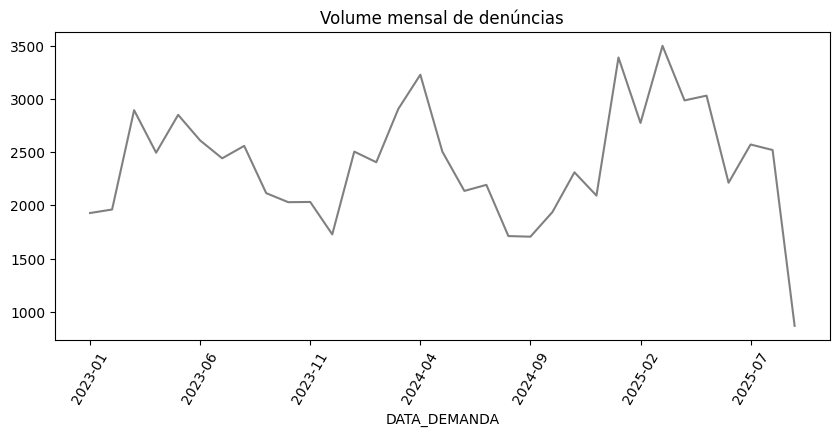

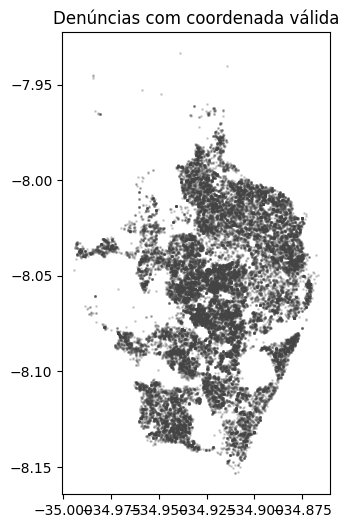

In [ ]:
tabela_perdas = pd.DataFrame(perdas)
display(tabela_perdas)

print("Volume por ano:\n", df.groupby("ANO_ARQUIVO").size())
print(f"\nCom coordenada válida: {df['COORD_VALIDA'].mean()*100:.1f}%")
print("\nTop 10 bairros:\n", df["BAIRRO"].value_counts().head(10))

mensal = df.groupby(df["DATA_DEMANDA"].dt.to_period("M").astype(str)).size()
mensal.plot(figsize=(10, 4), color="gray", title="Volume mensal de denúncias")
plt.xticks(rotation=60); plt.show()

v = df[df["COORD_VALIDA"]]
plt.figure(figsize=(6, 6))
plt.scatter(v["LON"], v["LAT"], s=1, alpha=0.2, color="#444")
plt.title("Denúncias com coordenada válida"); plt.gca().set_aspect("equal"); plt.show()

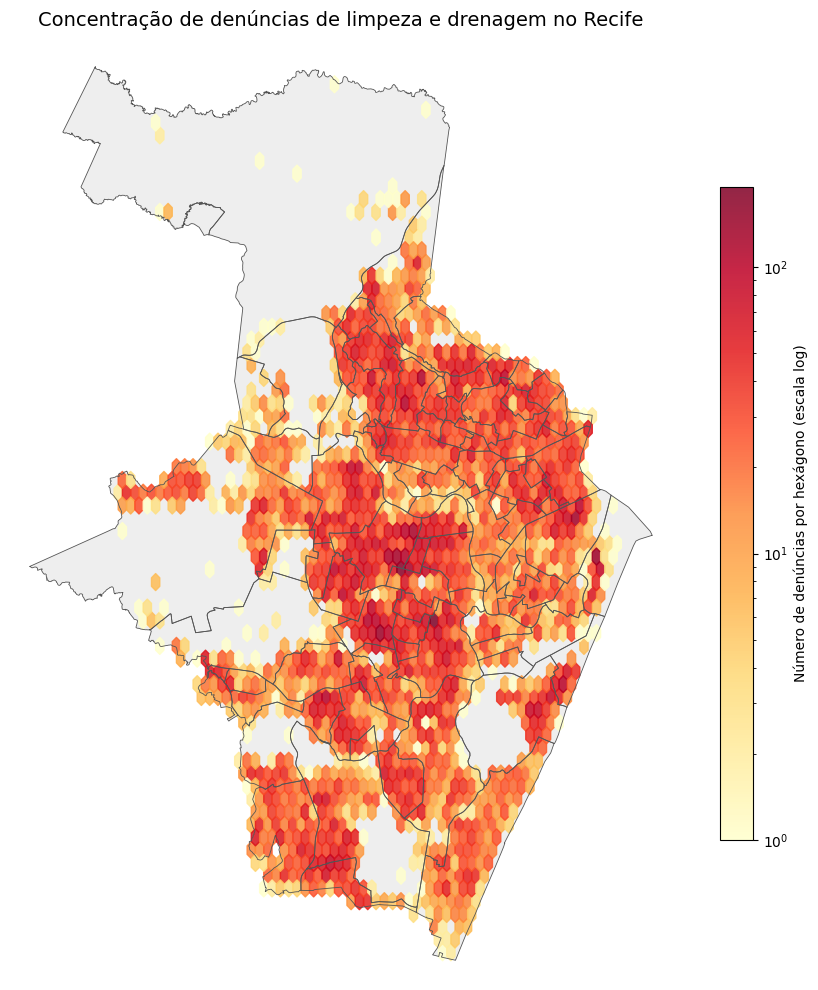

In [ ]:
import matplotlib.pyplot as plt

bairros = gpd.read_file("bairros.geojson").to_crs(epsg=4326)

fig, ax = plt.subplots(figsize=(10, 10))

# Fundo do mapa do Recife
bairros.plot(
    ax=ax,
    color="#eeeeee",
    edgecolor="none"
)

# Concentração das denúncias
hb = ax.hexbin(
    v["LON"],
    v["LAT"],
    gridsize=60,
    bins="log",
    mincnt=1,
    cmap="YlOrRd",
    alpha=0.85
)

# Limites dos bairros por cima dos hexágonos
bairros.boundary.plot(
    ax=ax,
    color="#555555",
    linewidth=0.6
)

# Mantém o enquadramento no território do Recife
xmin, ymin, xmax, ymax = bairros.total_bounds

ax.set_xlim(xmin - 0.005, xmax + 0.005)
ax.set_ylim(ymin - 0.005, ymax + 0.005)

barra = fig.colorbar(hb, ax=ax, shrink=0.7)
barra.set_label("Número de denúncias por hexágono (escala log)")

ax.set_title(
    "Concentração de denúncias de limpeza e drenagem no Recife",
    fontsize=14,
    pad=15
)

ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
df.to_parquet("156_limpo.parquet", index=False)
tabela_perdas.to_csv("tabela_perdas.csv", index=False)
situacoes.to_csv("situacoes_unicas.csv", index=False)

from google.colab import files
files.download("156_limpo.parquet")
files.download("tabela_perdas.csv")
files.download("situacoes_unicas.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>